In [2]:

import os
import requests

os.makedirs("/content/dataset", exist_ok=True)

files_to_download = {
    "KDDTrain+.txt":
        "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt",

    "KDDTest+.txt":
        "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"
}

for filename, url in files_to_download.items():

    print(f"\nDownloading {filename}...")

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    if len(response.content) < 1000:
        raise ValueError(f"Downloaded file is too small: {filename}")

    filepath = f"/content/dataset/{filename}"

    with open(filepath, "wb") as f:
        f.write(response.content)

    print("Downloaded successfully!")
    print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")

print("\nBoth dataset files are ready!")



Downloaded successfully!
File size: 18.22 MB

Downloaded successfully!
File size: 3.28 MB

Both dataset files are ready!


In [3]:
import os

print("Dataset folder contents:")

for file in os.listdir("/content/dataset"):
    print(file)

Dataset folder contents:
KDDTrain+.txt
KDDTest+.txt


NETWORK INTRUSION DETECTION USING BGWO

Dataset loaded successfully!
Training shape: (125973, 42)
Testing shape: (22544, 42)

Original features: 41
Encoded columns: 113

INITIAL WOLF POPULATION
----------------------------------------
Wolf 1: Fitness = 0.012798, Accuracy = 99.20%, Features = 20
Wolf 2: Fitness = 0.012052, Accuracy = 99.30%, Features = 21
Wolf 3: Fitness = 0.016514, Accuracy = 98.80%, Features = 19
Wolf 4: Fitness = 0.035826, Accuracy = 96.80%, Features = 17
Wolf 5: Fitness = 0.019226, Accuracy = 98.60%, Features = 22

STARTING BGWO OPTIMIZATION
Iteration 1/5 | Best Fitness: 0.012052 | Accuracy: 99.30% | Selected Features: 21
Iteration 2/5 | Best Fitness: 0.012052 | Accuracy: 99.30% | Selected Features: 21
Iteration 3/5 | Best Fitness: 0.012052 | Accuracy: 99.30% | Selected Features: 21
Iteration 4/5 | Best Fitness: 0.012052 | Accuracy: 99.30% | Selected Features: 21
Iteration 5/5 | Best Fitness: 0.012038 | Accuracy: 99.40% | Selected Features: 25

OPTIMAL FEATURE SELEC

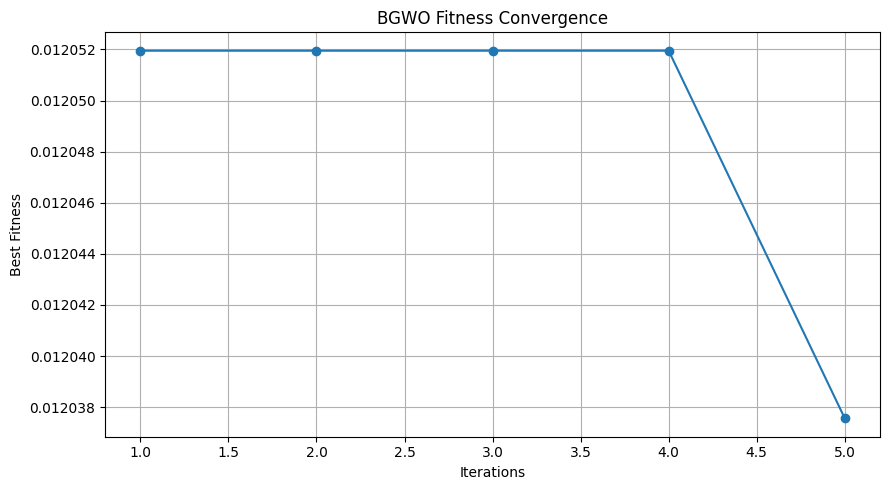

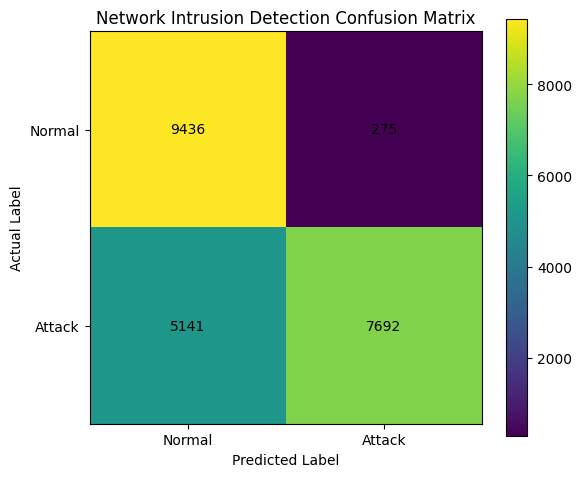


ALL RESULTS SAVED SUCCESSFULLY!

Generated files:

1. selected_features.csv
2. nids_results.csv
3. bgwo_convergence.png
4. nids_confusion_matrix.png



In [4]:

# ============================================================
# NETWORK INTRUSION DETECTION SYSTEM
# FEATURE SELECTION USING BINARY GREY WOLF OPTIMIZER (BGWO)
# Dataset: NSL-KDD
# Classifier: Random Forest
# Platform: Google Colab
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

TRAIN_PATH = "/content/dataset/KDDTrain+.txt"
TEST_PATH = "/content/dataset/KDDTest+.txt"

N_WOLVES = 5
MAX_ITER = 5

ALPHA_WEIGHT = 0.99
BETA_WEIGHT = 0.01

RANDOM_STATE = 42

# Initial experiment uses a subset for faster execution.
# Set to None for the complete training dataset.
MAX_TRAIN_ROWS = 5000

rng = np.random.default_rng(RANDOM_STATE)

# ============================================================
# 2. LOAD DATASET
# ============================================================

print("=" * 60)
print("NETWORK INTRUSION DETECTION USING BGWO")
print("=" * 60)

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError("Training dataset not found!")

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Testing dataset not found!")

train_df = pd.read_csv(TRAIN_PATH, header=None)
test_df = pd.read_csv(TEST_PATH, header=None)

columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate",
    "dst_host_srv_serror_rate",
    "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
    "label", "difficulty_level"
]

train_df.columns = columns
test_df.columns = columns

# Remove difficulty_level
train_df.drop(columns=["difficulty_level"], inplace=True)
test_df.drop(columns=["difficulty_level"], inplace=True)

# Convert labels into binary classes
# 0 = Normal, 1 = Attack

for df in [train_df, test_df]:
    df["label"] = (
        df["label"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.rstrip(".")
    )
    df["label"] = (df["label"] != "normal").astype(int)

print("\nDataset loaded successfully!")
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

# ============================================================
# 3. PREPARE TRAINING AND VALIDATION DATA
# ============================================================

if MAX_TRAIN_ROWS is not None and len(train_df) > MAX_TRAIN_ROWS:
    train_df, _ = train_test_split(
        train_df,
        train_size=MAX_TRAIN_ROWS,
        random_state=RANDOM_STATE,
        stratify=train_df["label"]
    )

X_raw = train_df.drop(columns=["label"])
y = train_df["label"].to_numpy()

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_test_raw = test_df.drop(columns=["label"])
y_test = test_df["label"].to_numpy()

# ============================================================
# 4. ENCODE CATEGORICAL FEATURES
# ============================================================

categorical_features = [
    "protocol_type", "service", "flag"
]

FEATURE_NAMES = list(X_raw.columns)
FEATURE_GROUPS = {}
train_parts = []
val_parts = []
test_parts = []

position = 0

for col in FEATURE_NAMES:

    if col in categorical_features:

        tr = pd.get_dummies(
            X_train_raw[col].astype(str),
            prefix=col,
            dtype=int
        )

        va = pd.get_dummies(
            X_val_raw[col].astype(str),
            prefix=col,
            dtype=int
        )

        te = pd.get_dummies(
            X_test_raw[col].astype(str),
            prefix=col,
            dtype=int
        )

        va = va.reindex(columns=tr.columns, fill_value=0)
        te = te.reindex(columns=tr.columns, fill_value=0)

    else:

        tr_values = pd.to_numeric(
            X_train_raw[col], errors="coerce"
        )

        median = tr_values.median()

        tr = tr_values.fillna(median).to_frame(col)

        va = pd.to_numeric(
            X_val_raw[col], errors="coerce"
        ).fillna(median).to_frame(col)

        te = pd.to_numeric(
            X_test_raw[col], errors="coerce"
        ).fillna(median).to_frame(col)

    tr_array = tr.to_numpy(dtype=float)
    va_array = va.to_numpy(dtype=float)
    te_array = te.to_numpy(dtype=float)

    width = tr_array.shape[1]

    FEATURE_GROUPS[col] = list(
        range(position, position + width)
    )

    train_parts.append(tr_array)
    val_parts.append(va_array)
    test_parts.append(te_array)

    position += width

X_train = np.concatenate(train_parts, axis=1)
X_val = np.concatenate(val_parts, axis=1)
X_test = np.concatenate(test_parts, axis=1)

TOTAL_FEATURES = len(FEATURE_NAMES)

print("\nOriginal features:", TOTAL_FEATURES)
print("Encoded columns:", X_train.shape[1])

# ============================================================
# 5. CONVERT BINARY FEATURE SELECTION TO COLUMNS
# ============================================================

def get_selected_columns(binary_position):

    selected = np.where(binary_position == 1)[0]

    columns = []

    for index in selected:
        name = FEATURE_NAMES[index]
        columns.extend(FEATURE_GROUPS[name])

    return columns


# ============================================================
# 6. FITNESS FUNCTION
# ============================================================

def fitness_function(binary_position):

    selected_count = np.sum(binary_position)

    if selected_count == 0:
        return 1.0, 0.0

    selected_columns = get_selected_columns(
        binary_position
    )

    model = RandomForestClassifier(
        n_estimators=50,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced_subsample"
    )

    model.fit(
        X_train[:, selected_columns],
        y_train
    )

    predictions = model.predict(
        X_val[:, selected_columns]
    )

    accuracy = accuracy_score(y_val, predictions)

    error = 1 - accuracy

    ratio = selected_count / TOTAL_FEATURES

    fitness = (
        ALPHA_WEIGHT * error
        + BETA_WEIGHT * ratio
    )

    return fitness, accuracy


# ============================================================
# 7. INITIALIZE GREY WOLF POPULATION
# ============================================================

positions = rng.uniform(
    0, 1,
    size=(N_WOLVES, TOTAL_FEATURES)
)

binary_positions = (
    positions >= 0.5
).astype(int)

fitness_values = np.zeros(N_WOLVES)
accuracies = np.zeros(N_WOLVES)

print("\nINITIAL WOLF POPULATION")
print("-" * 40)

for i in range(N_WOLVES):

    if binary_positions[i].sum() == 0:
        binary_positions[i, rng.integers(TOTAL_FEATURES)] = 1

    fitness_values[i], accuracies[i] = fitness_function(
        binary_positions[i]
    )

    print(
        f"Wolf {i+1}: "
        f"Fitness = {fitness_values[i]:.6f}, "
        f"Accuracy = {accuracies[i]*100:.2f}%, "
        f"Features = {binary_positions[i].sum()}"
    )


# ============================================================
# 8. IDENTIFY ALPHA, BETA AND DELTA
# ============================================================

def get_leaders():

    order = np.argsort(fitness_values)

    a, b, d = order[:3]

    return (
        positions[a].copy(),
        positions[b].copy(),
        positions[d].copy(),
        binary_positions[a].copy(),
        fitness_values[a],
        accuracies[a]
    )


(
    X_alpha, X_beta, X_delta,
    B_alpha, F_alpha, Alpha_accuracy
) = get_leaders()

best_position = X_alpha.copy()
best_binary = B_alpha.copy()
best_fitness = F_alpha
best_accuracy = Alpha_accuracy

# ============================================================
# 9. BINARY GREY WOLF OPTIMIZATION
# ============================================================

convergence_curve = []

print("\nSTARTING BGWO OPTIMIZATION")
print("=" * 60)

for t in range(1, MAX_ITER + 1):

    a = 2 - 2 * (t / MAX_ITER)

    for i in range(N_WOLVES):

        X = positions[i].copy()

        X1 = np.zeros(TOTAL_FEATURES)
        X2 = np.zeros(TOTAL_FEATURES)
        X3 = np.zeros(TOTAL_FEATURES)

        for j in range(TOTAL_FEATURES):

            # Alpha wolf
            r1, r2 = rng.random(2)

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(
                C1 * X_alpha[j] - X[j]
            )

            X1[j] = X_alpha[j] - A1 * D_alpha

            # Beta wolf
            r1, r2 = rng.random(2)

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(
                C2 * X_beta[j] - X[j]
            )

            X2[j] = X_beta[j] - A2 * D_beta

            # Delta wolf
            r1, r2 = rng.random(2)

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(
                C3 * X_delta[j] - X[j]
            )

            X3[j] = X_delta[j] - A3 * D_delta

        # Calculate new position
        new_position = (X1 + X2 + X3) / 3

        # Sigmoid transfer function
        sigmoid = 1 / (
            1 + np.exp(
                -np.clip(new_position, -500, 500)
            )
        )

        # Binary conversion
        new_binary = (
            rng.random(TOTAL_FEATURES) < sigmoid
        ).astype(int)

        if new_binary.sum() == 0:
            new_binary[np.argmax(sigmoid)] = 1

        positions[i] = new_position
        binary_positions[i] = new_binary

    # Recalculate fitness
    for i in range(N_WOLVES):

        fitness_values[i], accuracies[i] = fitness_function(
            binary_positions[i]
        )

    # Update leaders
    (
        X_alpha, X_beta, X_delta,
        B_alpha, F_alpha, Alpha_accuracy
    ) = get_leaders()

    # Preserve global best
    if F_alpha < best_fitness:

        best_fitness = F_alpha
        best_position = X_alpha.copy()
        best_binary = B_alpha.copy()
        best_accuracy = Alpha_accuracy

    convergence_curve.append(best_fitness)

    print(
        f"Iteration {t}/{MAX_ITER} | "
        f"Best Fitness: {best_fitness:.6f} | "
        f"Accuracy: {best_accuracy*100:.2f}% | "
        f"Selected Features: {best_binary.sum()}"
    )


# ============================================================
# 10. DISPLAY OPTIMAL FEATURES
# ============================================================

selected_indices = np.where(best_binary == 1)[0]

selected_features = [
    FEATURE_NAMES[i] for i in selected_indices
]

selected_columns = get_selected_columns(best_binary)

print("\n" + "=" * 60)
print("OPTIMAL FEATURE SELECTION RESULTS")
print("=" * 60)

for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

print("\nTotal original features:", TOTAL_FEATURES)
print("Selected features:", len(selected_features))

reduction = (
    1 - len(selected_features) / TOTAL_FEATURES
) * 100

print(f"Feature reduction: {reduction:.2f}%")
print(f"Validation accuracy: {best_accuracy*100:.2f}%")
print(f"Best fitness: {best_fitness:.6f}")


# ============================================================
# 11. FINAL RANDOM FOREST CLASSIFICATION
# ============================================================

print("\nFINAL TESTING")

final_model = RandomForestClassifier(
    n_estimators=150,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

final_model.fit(
    X_train[:, selected_columns],
    y_train
)

test_predictions = final_model.predict(
    X_test[:, selected_columns]
)

accuracy = accuracy_score(y_test, test_predictions)

precision = precision_score(
    y_test, test_predictions, zero_division=0
)

recall = recall_score(
    y_test, test_predictions, zero_division=0
)

f1 = f1_score(
    y_test, test_predictions, zero_division=0
)

print("\n" + "=" * 60)
print("FINAL NETWORK INTRUSION DETECTION RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Normal", "Attack"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)


# ============================================================
# 12. SAVE OUTPUT FILES
# ============================================================

pd.DataFrame({
    "Selected_Feature": selected_features
}).to_csv(
    "/content/selected_features.csv",
    index=False
)

pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Best Fitness",
        "Total Features",
        "Selected Features",
        "Feature Reduction"
    ],
    "Value": [
        best_accuracy,
        accuracy,
        precision,
        recall,
        f1,
        best_fitness,
        TOTAL_FEATURES,
        len(selected_features),
        reduction
    ]
}).to_csv(
    "/content/nids_results.csv",
    index=False
)


# ============================================================
# 13. BGWO CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, MAX_ITER + 1),
    convergence_curve,
    marker="o"
)

plt.title("BGWO Fitness Convergence")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "/content/bgwo_convergence.png"
)

plt.show()


# ============================================================
# 14. CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest")

plt.title("Network Intrusion Detection Confusion Matrix")

plt.colorbar()

plt.xticks([0, 1], ["Normal", "Attack"])
plt.yticks([0, 1], ["Normal", "Attack"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):

        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    "/content/nids_confusion_matrix.png"
)

plt.show()


# ============================================================
# 15. DISPLAY SAVED FILES
# ============================================================

print("\nALL RESULTS SAVED SUCCESSFULLY!")

print("""
Generated files:

1. selected_features.csv
2. nids_results.csv
3. bgwo_convergence.png
4. nids_confusion_matrix.png
""")
